# Прогнозирование направления свечи следующего торгового дня

**Цель:** по историческим дневным OHLCV-данным предсказать, закроется ли следующий торговый день не ниже цены своего открытия ("бычья" свеча) или ниже ("медвежья" свеча).

**План работы:**
1. [Загрузка и приведение типов](#scrollTo=8d12bf53)
2. [Проверка качества данных](#scrollTo=09fc961f)
3. [Определение смысла целевой переменной](#scrollTo=2f62069b)
4. [EDA](#scrollTo=w3LKeEOl26Yf)
5. [Feature engineering](#scrollTo=Y_-flL9vERWB)
6. [Train/test split](#scrollTo=iuJL13chwJ6k)
7. [Baseline и основная модель](#scrollTo=e3fd5b32)
8. [Оценка устойчивости: кросс-валидация и подбор гиперпараметров](#scrollTo=yAKGesw0RIa3)
9. [Прямая статистическая проверка сигнала](#scrollTo=WJ_tfv9cT-U5)
10. [Итоговые выводы](#scrollTo=qchOqmYxVJeK)

## 0. Импорт основных зависимостей

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

RANDOM_STATE = 42  # фиксирован для воспроизводимости экспериментов

## 1. Загрузка данных

Файл лежит на Яндекс.Диске по публичной ссылке (странице просмотра, не прямому файлу), поэтому используем официальный API Яндекс.Диска, который по публичной ссылке отдаёт временную прямую ссылку на скачивание.

In [ ]:
def download_from_yandex_disk(public_url: str, save_path: str) -> str:
    """
    Скачивает файл с Яндекс.Диска по публичной ссылке.
    API возвращает JSON с полем 'href' - это прямая ссылка на скачивание.
    """
    API_URL = 'https://cloud-api.yandex.net/v1/disk/public/resources/download'
    response = requests.get(API_URL, params={'public_key': public_url})
    response.raise_for_status()
    download_href = response.json()['href']

    file_response = requests.get(download_href)
    file_response.raise_for_status()

    with open(save_path, 'wb') as f:
        f.write(file_response.content)

    return save_path


DATA_URL = 'https://disk.360.yandex.ru/i/FoATHfhlshcDlQ'
LOCAL_PATH = 'price_data.xlsx'

download_from_yandex_disk(DATA_URL, LOCAL_PATH)
print(f'Файл сохранён: {LOCAL_PATH}')

Файл сохранён: price_data.xlsx


In [ ]:
df = pd.read_excel(LOCAL_PATH, parse_dates=['date'])
df = df.sort_values('date').reset_index(drop=True)  # гарантируем хронологический порядок (важно time-series сплита и rolling-признаков)

print(df.shape)
df.head()

/usr/local/lib/python3.13/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


(2507, 7)


,date,open,high,low,close,vol,target
0,2014-06-16,"2092,2","2153,3","2067,3",2149,3720757,0
1,2014-06-17,"2205,1","2205,1","2122,5",2130,1494451,0
2,2014-06-18,2135,"2152,3","2121,8","2126,9",1129635,0
3,2014-06-19,2140,"2147,9",2112,"2112,1",1140105,0
4,2014-06-20,2119,"2127,3","2086,1",2100,1067446,0


### Приведение типов

`open`/`high`/`low`/`close` читаются как `object` (строки), потому что исходный файл использует запятую как десятичный разделитель.

In [ ]:
price_cols = ['open', 'high', 'low', 'close']

for col in price_cols:
    df[col] = df[col].astype(str).str.replace(',', '.', regex=False).astype(float)

assert df[price_cols].isna().sum().sum() == 0, 'После конвертации появились NaN'
print(df.dtypes)

date      datetime64[ns]
open             float64
high             float64
low              float64
close            float64
vol                int64
target             int64
dtype: object


## 2. Проверка качества данных

Проверяем пропуски, дубликаты, логическую целостность OHLC (high должен быть не меньше max(open, close, low), и наоборот).

In [ ]:
print('Пропуски по столбцам:')
print(df.isna().sum(), end='\n\n')
print('Полных дубликатов строк:', df.duplicated().sum())
print('Дубликатов по дате:', df['date'].duplicated().sum())
print('Даты строго по возрастанию:', df['date'].is_monotonic_increasing)

bad_rows = df[(df['high'] < df[['open', 'close', 'low']].max(axis=1)) |
              (df['low'] > df[['open', 'close', 'high']].min(axis=1))]
print(f'Строк с нарушением целостности OHLC: {len(bad_rows)}')

Пропуски по столбцам:
date      0
open      0
high      0
low       0
close     0
vol       0
target    0
dtype: int64

Полных дубликатов строк: 0
Дубликатов по дате: 0
Даты строго по возрастанию: True
Строк с нарушением целостности OHLC: 0


In [ ]:
df.describe()

,date,open,high,low,close,vol,target
count,2507,2507.000000,2507.000000,2507.000000,2507.000000,2.507000e+03,2507.000000
mean,2019-06-09 15:13:16.968488192,4460.243638,4511.057519,4405.094655,4461.615836,9.725856e+05,0.512964
min,2014-06-16 00:00:00,1916.000000,1949.000000,1911.500000,1925.100000,5.404300e+04,0.000000
25%,2016-12-08 12:00:00,2939.050000,2964.750000,2901.750000,2936.500000,5.602675e+05,0.000000
50%,2019-06-04 00:00:00,4452.000000,4512.500000,4381.500000,4456.000000,8.043300e+05,1.000000
75%,2021-11-24 12:00:00,5621.500000,5692.500000,5566.500000,5618.750000,1.197488e+06,1.000000
max,2024-06-14 00:00:00,8152.500000,8175.000000,8080.000000,8152.000000,7.526760e+06,1.000000
std,NaN,1601.778261,1614.741585,1585.718511,1601.606745,6.599666e+05,0.499932


## 3. Определение смысла целевой переменной

В датасете `target` дан без описания, как именно он посчитан.

Проверяем несколько гипотез через сопоставление с историческими OHLC-значениями:

In [ ]:
hypotheses = {
    'close(t+1) > close(t)  [междневная доходность]': (df['close'].shift(-1) > df['close']),
    'close(t+1) >= open(t+1)  [свеча дня t+1]': (df['close'].shift(-1) >= df['open'].shift(-1)),
    'open(t+1)  > close(t) [гэп]': (df['open'].shift(-1) > df['close']),
    'close(t+2) > close(t)  [горизонт 2 дня]': (df['close'].shift(-2) > df['close']),
    'close(t+1) > MA20(t)': (df['close'].shift(-1) > df['close'].rolling(20).mean()),
}

for name, hyp in hypotheses.items():
    hyp = hyp.astype(float)
    valid = hyp.notna() & df['target'].notna()
    match = (df['target'][valid] == hyp[valid]).mean()
    print(f'{name:45s} match = {match:.4f}')

close(t+1) > close(t)  [междневная доходность] match = 0.8987
close(t+1) >= open(t+1)  [свеча дня t+1]      match = 1.0000
open(t+1)  > close(t) [гэп]                   match = 0.4922
close(t+2) > close(t)  [горизонт 2 дня]       match = 0.7411
close(t+1) > MA20(t)                          match = 0.6262


**Результат:** гипотеза `close(t+1) >= open(t+1)` даёт совпадение 100%.

Это индикатор, который говорит о том, была ли свеча дня `t+1` бычьей, т.е. закрылся ли день не ниже, чем он открылся. Предсказание данного индикатора по историческим данным является целью дальнейшей работы.

## 4. EDA

Проверяем баланс классов и динамику ряда:

target
1    0.512964
0    0.487036
Name: proportion, dtype: float64


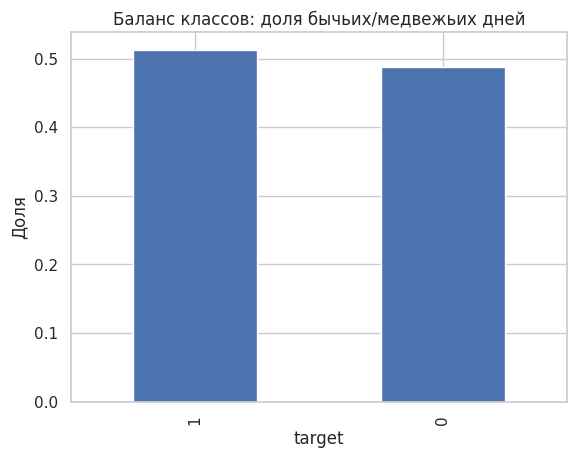

In [ ]:
target_counts = df['target'].value_counts(normalize=True)
print(target_counts)

target_counts.plot(kind='bar', title='Баланс классов: доля бычьих/медвежьих дней', xlabel='target', ylabel='Доля')
plt.show()

Классы сбалансированы (~51/49) - можно опираться на accuracy наравне с ROC-AUC, без риска, что дисбаланс исказит интерпретацию.

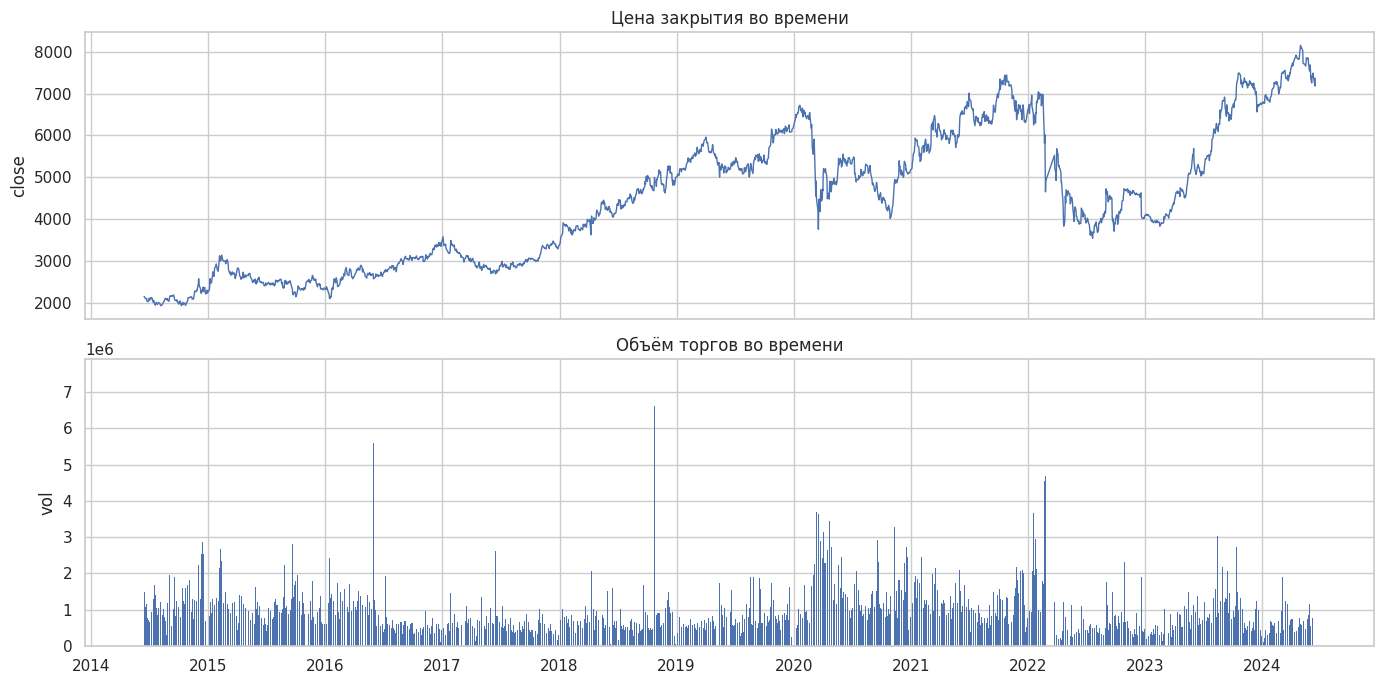

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

axes[0].plot(df['date'], df['close'], linewidth=1)
axes[0].set_title('Цена закрытия во времени')
axes[0].set_ylabel('close')

axes[1].bar(df['date'], df['vol'], width=1, edgecolor='none')
axes[1].set_title('Объём торгов во времени')
axes[1].set_ylabel('vol')

plt.tight_layout()
plt.show()

### Доля бычьих дней по годам

Имеет смысл проверить как часто день закрывается не ниже открытия, а также меняется ли эта доля во времени (если сильно дрейфует, это сигнал нестационарности целевой переменной).

date
2014    0.524823
2015    0.504000
2016    0.591270
2017    0.492063
2018    0.519685
2019    0.559524
2020    0.508000
2021    0.494118
2022    0.444444
2023    0.509881
2024    0.482456
Name: is_bullish, dtype: float64


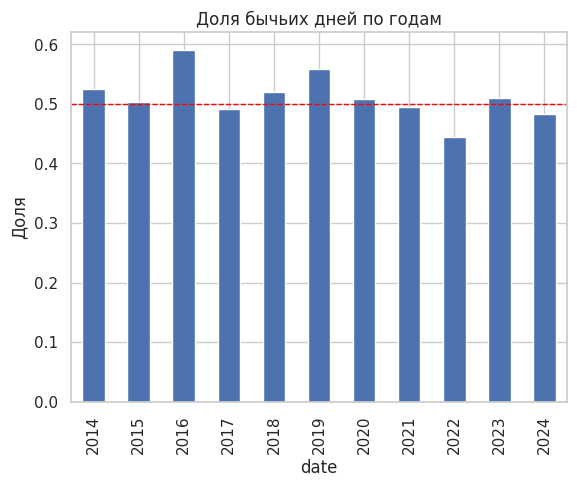

In [ ]:
df['is_bullish'] = (df['close'] >= df['open']).astype(int)

bullish_by_year = df.groupby(df['date'].dt.year)['is_bullish'].mean()
print(bullish_by_year)

bullish_by_year.plot(kind='bar', title='Доля бычьих дней по годам', ylabel='Доля')
plt.axhline(0.5, color='red', linestyle='--', linewidth=1)
plt.show()

## 5. Feature engineering

Два источника признаков:

**1) Трендовые/моментум-индикаторы** (доходности, волатильность, RSI, MACD, Bollinger, ATR, дистанции от MA) - общий рыночный контекст (тренд, волатильность) может влиять на то, как закроется следующий день.

**2) Признаки паттерна направления свечей**. Если target - это бычесть/медвежесть дня `t+1`, то естественный кандидат в предикторы - недавняя история бычести/медвежести предыдущих дней (возможна автокорреляция направления свечей, например из-за моментума внутри дня, переходящего на следующий).

Все признаки строятся только из данных до дня `t` включительно.

### 5.1 Трендовые/моментум-признаки

In [ ]:
for lag in [1, 3, 5, 10]:
    df[f'return_{lag}d'] = df['close'].pct_change(lag)

df['hl_range'] = (df['high'] - df['low']) / df['close']
df['oc_change'] = (df['close'] - df['open']) / df['open']

for window in [5, 10, 20]:
    df[f'ma_return_{window}d'] = df['close'].pct_change().rolling(window).mean()
    df[f'volatility_{window}d'] = df['close'].pct_change().rolling(window).std()

df['log_vol'] = np.log1p(df['vol'])
df['relative_vol'] = df['vol'] / df['vol'].rolling(20).mean()

delta = df['close'].diff()
gain = delta.clip(lower=0).rolling(14).mean()
loss = (-delta.clip(upper=0)).rolling(14).mean()
rs = gain / loss
df['rsi_14'] = 100 - (100 / (1 + rs))

ema_12 = df['close'].ewm(span=12, adjust=False).mean()
ema_26 = df['close'].ewm(span=26, adjust=False).mean()
df['macd'] = ema_12 - ema_26
df['macd_signal'] = df['macd'].ewm(span=9, adjust=False).mean()
# MACD в абсолютных единицах цены зависит от масштаба актива - добавляем нормализованную версию, чтобы не использовать абсолютный уровень цены
df['macd_normalized'] = df['macd'] / df['close']
df['macd_signal_normalized'] = df['macd_signal'] / df['close']

ma20 = df['close'].rolling(20).mean()
std20 = df['close'].rolling(20).std()
df['bb_position'] = (df['close'] - ma20) / (2 * std20)

high_low = df['high'] - df['low']
high_close = (df['high'] - df['close'].shift()).abs()
low_close = (df['low'] - df['close'].shift()).abs()
true_range = pd.concat([high_low, high_close, low_close], axis=1).max(axis=1)
df['atr_14'] = true_range.rolling(14).mean()

for window in [50, 100, 200]:
    df[f'dist_ma_{window}'] = (df['close'] - df['close'].rolling(window).mean()) / df['close']

df['day_of_week'] = df['date'].dt.dayofweek
df['month'] = df['date'].dt.month

print('Трендовых признаков создано:', df.shape[1])

Трендовых признаков создано: 34


### 5.2 Признаки паттерна направления свечей

### Длина серии подряд идущих дней одного направления (momentum направления свечи)

In [ ]:
direction_change = df['is_bullish'] != df['is_bullish'].shift(1)
streak_id = direction_change.cumsum()
df['streak_length'] = df.groupby(streak_id).cumcount() + 1
# знак серии: положительная длина для бычьей серии, отрицательная для медвежьей
df['streak_signed'] = df['streak_length'] * np.where(df['is_bullish'] == 1, 1, -1)

### Доля бычьих дней в скользящем окне

In [ ]:
for window in [3, 5, 10, 20]:
    df[f'bullish_share_{window}d'] = df['is_bullish'].rolling(window).mean()

### Гэп на открытии относительно вчерашнего закрытия

In [ ]:
df['gap_open'] = (df['open'] - df['close'].shift(1)) / df['close'].shift(1)

print('Итоговое число столбцов:', df.shape[1])
df.tail()

Итоговое число столбцов: 41


,date,open,high,low,close,vol,target,is_bullish,return_1d,return_3d,return_5d,return_10d,hl_range,oc_change,ma_return_5d,volatility_5d,ma_return_10d,volatility_10d,ma_return_20d,volatility_20d,log_vol,relative_vol,rsi_14,macd,macd_signal,macd_normalized,macd_signal_normalized,bb_position,atr_14,dist_ma_50,dist_ma_100,dist_ma_200,day_of_week,month,streak_length,streak_signed,bullish_share_3d,bullish_share_5d,bullish_share_10d,bullish_share_20d,gap_open
2502,2024-06-07,7401.0,7599.0,7401.0,7489.0,1063345,0,1,0.012301,0.008484,0.018150,-0.029922,0.026439,0.011890,0.003690,0.014697,-0.002903,0.016965,-0.001393,0.013204,13.876931,1.378711,35.960991,-103.049146,-77.845315,-0.013760,-0.010395,-0.353228,188.178571,-0.035083,0.000519,0.035843,4,6,1,1,0.333333,0.4,0.4,0.40,0.000406
2503,2024-06-10,7520.0,7523.5,7261.0,7315.0,785549,0,0,-0.023234,-0.013153,0.008687,-0.030034,0.035885,-0.027261,0.001857,0.017725,-0.002915,0.016980,-0.002396,0.014079,13.574139,1.000338,30.841121,-111.243202,-84.524892,-0.015208,-0.011555,-0.732866,198.928571,-0.059059,-0.023809,0.012463,0,6,1,-1,0.333333,0.4,0.4,0.40,0.004139
2504,2024-06-11,7315.0,7370.0,7235.0,7290.0,698787,1,0,-0.003418,-0.014599,-0.018314,-0.039526,0.018519,-0.003418,-0.003625,0.012691,-0.003899,0.016660,-0.002456,0.014081,13.457103,0.878568,30.907781,-118.389620,-91.297838,-0.016240,-0.012524,-0.708021,203.285714,-0.061663,-0.027914,0.008726,1,6,2,-2,0.333333,0.2,0.3,0.40,0.000000
2505,2024-06-13,7050.0,7276.0,6923.0,7178.5,1277680,1,1,-0.015295,-0.041461,-0.031568,-0.065786,0.049175,0.018227,-0.006320,0.013609,-0.006667,0.015938,-0.003113,0.014370,14.060557,1.527066,27.571042,-131.534083,-99.345087,-0.018323,-0.013839,-0.848160,223.535714,-0.076828,-0.044359,-0.006909,3,6,1,1,0.333333,0.4,0.3,0.45,-0.032922
2506,2024-06-14,7198.0,7403.5,7181.5,7368.0,735998,0,1,0.026398,0.007245,-0.004055,-0.026298,0.030130,0.023618,-0.000650,0.020196,-0.002505,0.018657,-0.002182,0.015658,13.508984,0.868365,38.615783,-125.216678,-104.519405,-0.016995,-0.014186,-0.383274,228.357143,-0.048268,-0.018215,0.018623,4,6,2,2,0.666667,0.6,0.4,0.45,0.002716


### Rolling-признаки создают NaN в начале ряда - отсекаем эти строки

In [ ]:
print('NaN по колонкам до отсечения:')
print(df.isna().sum()[df.isna().sum() > 0])

df = df.dropna().reset_index(drop=True)
print('\nРазмер после отсечения:', df.shape)

NaN по колонкам до отсечения:
return_1d              1
return_3d              3
return_5d              5
return_10d            10
ma_return_5d           5
volatility_5d          5
ma_return_10d         10
volatility_10d        10
ma_return_20d         20
volatility_20d        20
relative_vol          19
rsi_14                14
bb_position           19
atr_14                13
dist_ma_50            49
dist_ma_100           99
dist_ma_200          199
bullish_share_3d       2
bullish_share_5d       4
bullish_share_10d      9
bullish_share_20d     19
gap_open               1
dtype: int64

Размер после отсечения: (2308, 41)


### Проверка, коррелируют ли candle-pattern признаки с target

In [ ]:
feature_cols = [c for c in df.columns if c not in ['date', 'open', 'high', 'low', 'close', 'vol', 'target']]
corr_with_target = df[feature_cols].corrwith(df['target']).sort_values(key=abs, ascending=False)
print(corr_with_target)

volatility_20d           -0.054942
relative_vol              0.054847
atr_14                   -0.050980
log_vol                   0.047839
volatility_10d           -0.044925
volatility_5d            -0.034009
is_bullish                0.029652
return_5d                 0.027298
bb_position               0.025925
macd                      0.025301
ma_return_5d              0.024549
dist_ma_50                0.024052
macd_normalized           0.022589
macd_signal_normalized    0.021695
macd_signal               0.020692
month                     0.020625
ma_return_20d             0.020464
bullish_share_5d          0.020381
hl_range                  0.019815
dist_ma_100               0.019579
dist_ma_200               0.018532
streak_signed             0.017134
bullish_share_3d          0.016507
streak_length             0.015058
return_10d                0.014150
ma_return_10d             0.011393
return_1d                 0.010470
oc_change                 0.009596
bullish_share_20d   

**Результат:** candle-pattern признаки (`is_bullish`, `streak_signed`, `bullish_share_*`, `gap_open`) оказались связаны с target слабее, чем volatility/volume-признаки (`volatility_20d`, `relative_vol`, `atr_14`).

Максимальная корреляция составляет `~0.055`. Это значит, что гипотеза "направление свечи `t+1` объясняется инерцией направления предыдущих свечей" эмпирически не подтвердилась.

## 6. Train/test split

Обычное разделение со случайным перемешиванием здесь недопустимо: признаки на основе скользящих окон для дня `t` используют данные из диапазона `[t-w, t]`. Если перемешать строки случайно, в train может попасть день, чей признак рассчитан по окну, включающему день, отнесённый к test - это утечка сырых данных через скользящие окна. Разбиение будет происходить строго по хронологии: train - прошлое, test - будущее, как это будет происходить при реальном использовании модели.

In [ ]:
TEST_SIZE = 0.2
split_idx = int(len(df) * (1 - TEST_SIZE))
split_date = df.iloc[split_idx]['date']

train_df = df.iloc[:split_idx].copy()
test_df = df.iloc[split_idx:].copy()

print(f'Дата разреза: {split_date.date()}')
print(f'Train: {train_df.shape[0]} строк, {train_df["date"].min().date()} - {train_df["date"].max().date()}')
print(f'Test: {test_df.shape[0]} строк, {test_df["date"].min().date()} - {test_df["date"].max().date()}')

print('\nБаланс классов в train:')
print(train_df['target'].value_counts(normalize=True))
print('\nБаланс классов в test:')
print(test_df['target'].value_counts(normalize=True))

Дата разреза: 2022-08-19
Train: 1846 строк, 2015-03-31 - 2022-08-18
Test: 462 строк, 2022-08-19 - 2024-06-14

Баланс классов в train:
target
1    0.517876
0    0.482124
Name: proportion, dtype: float64

Баланс классов в test:
target
0    0.506494
1    0.493506
Name: proportion, dtype: float64


In [ ]:
# модель использует только производные признаки без абсолютных уровней цены
feature_cols = [c for c in df.columns if c not in ['date', 'open', 'high', 'low', 'close', 'vol', 'target']]

X_train, y_train = train_df[feature_cols], train_df['target']
X_test, y_test = test_df[feature_cols], test_df['target']

print(f'Признаков: {len(feature_cols)}')
print(feature_cols)

Признаков: 34
['is_bullish', 'return_1d', 'return_3d', 'return_5d', 'return_10d', 'hl_range', 'oc_change', 'ma_return_5d', 'volatility_5d', 'ma_return_10d', 'volatility_10d', 'ma_return_20d', 'volatility_20d', 'log_vol', 'relative_vol', 'rsi_14', 'macd', 'macd_signal', 'macd_normalized', 'macd_signal_normalized', 'bb_position', 'atr_14', 'dist_ma_50', 'dist_ma_100', 'dist_ma_200', 'day_of_week', 'month', 'streak_length', 'streak_signed', 'bullish_share_3d', 'bullish_share_5d', 'bullish_share_10d', 'bullish_share_20d', 'gap_open']


## 7. Baseline и основная модель

### 7.1 Baseline

В качестве точки отсчёта для сравнения с основной моделью используем константный предиктор как наиболее примитивный метод предсказания и логистическую регрессию для возможного извлечения линейной структуры из признаков

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report

# Константный предиктор (самый частый класс в train)
dummy = DummyClassifier(strategy='most_frequent', random_state=RANDOM_STATE)
dummy.fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)

print('Dummy (most frequent)')
print(f'Accuracy: {accuracy_score(y_test, dummy_pred):.4f}')
print(f'F1:       {f1_score(y_test, dummy_pred):.4f}')

# Логистическая регрессия
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)  # скейлер обучается только на train, чтобы не допустить утечку из test
X_test_scaled = scaler.transform(X_test)

logreg = LogisticRegression(random_state=RANDOM_STATE, max_iter=1000)
logreg.fit(X_train_scaled, y_train)
logreg_pred = logreg.predict(X_test_scaled)
logreg_proba = logreg.predict_proba(X_test_scaled)[:, 1]

print('\nLogistic Regression')
print(f'Accuracy: {accuracy_score(y_test, logreg_pred):.4f}')
print(f'F1:       {f1_score(y_test, logreg_pred):.4f}')
print(f'ROC-AUC:  {roc_auc_score(y_test, logreg_proba):.4f}')

Dummy (most frequent)
Accuracy: 0.4935
F1:       0.6609

Logistic Regression
Accuracy: 0.5000
F1:       0.5237
ROC-AUC:  0.5109


**Важно:** F1 считается для класса, который dummy предсказывает всегда, из-за чего может выглядеть обманчиво высоким при сбалансированных классах. Основные метрики - ROC-AUC и accuracy.

### 7.2. Градиентный бустинг

Градиентный бустинг хорошо работает с нелинейными зависимостями между признаками и не требует их масштабирования.

Сначала реализована конфигурация без регуляризации, чтобы явно увидеть, что происходит при переобучении, затем - регуляризованная версия с early stopping.

In [ ]:
import lightgbm as lgb

### 7.2.1 Без регуляризации

In [ ]:
lgb_naive = lgb.LGBMClassifier(
    n_estimators=200, max_depth=4, learning_rate=0.05, num_leaves=15,
    random_state=RANDOM_STATE, verbose=-1
)
lgb_naive.fit(X_train, y_train)

pred_train_naive = lgb_naive.predict(X_train)
pred_test_naive = lgb_naive.predict(X_test)

print('LightGBM без регуляризации')
print(f'Accuracy train: {accuracy_score(y_train, pred_train_naive):.4f}')
print(f'Accuracy test:  {accuracy_score(y_test, pred_test_naive):.4f}')
print(f'Разрыв train-test: {accuracy_score(y_train, pred_train_naive) - accuracy_score(y_test, pred_test_naive):.4f}')

LightGBM без регуляризации
Accuracy train: 0.8684
Accuracy test:  0.5065
Разрыв train-test: 0.3619


Большой разрыв train/test - модель заучивает шум обучающей выборки, а не обобщаемую закономерность. Финансовые данные с ~30 признаками на ~1800 строк train легко переобучаются без регуляризации.

### 7.2.2 Финальная модель с регуляризацией и early stopping

In [ ]:
val_split_idx = int(len(X_train) * 0.8)
X_tr, X_val = X_train.iloc[:val_split_idx], X_train.iloc[val_split_idx:]
y_tr, y_val = y_train.iloc[:val_split_idx], y_train.iloc[val_split_idx:]

lgb_model = lgb.LGBMClassifier(
    n_estimators=500,        # заведомо много (early stopping остановит раньше)
    max_depth=3,
    learning_rate=0.03,
    num_leaves=7,
    min_child_samples=50,    # минимум объектов - защита от переобучения на выбросах
    subsample=0.7,           # используется часть строк на каждой итерации
    colsample_bytree=0.7,    # и часть признаков на каждое дерево
    reg_alpha=0.5,
    reg_lambda=0.5,
    random_state=RANDOM_STATE,
    verbose=-1
)

lgb_model.fit(
    X_tr, y_tr,
    eval_set=[(X_val, y_val)],
    eval_metric='auc',
    callbacks=[lgb.early_stopping(stopping_rounds=30, verbose=False)]
)

print(f'Остановка на {lgb_model.best_iteration_} деревьях (из 500 заданных)')

pred_train = lgb_model.predict(X_train)
pred_test = lgb_model.predict(X_test)
proba_test = lgb_model.predict_proba(X_test)[:, 1]

print(f'\nAccuracy train: {accuracy_score(y_train, pred_train):.4f}')
print(f'Accuracy test: {accuracy_score(y_test, pred_test):.4f}')
print(f'ROC-AUC test: {roc_auc_score(y_test, proba_test):.4f}')
print(f'Разрыв train-test: {accuracy_score(y_train, pred_train) - accuracy_score(y_test, pred_test):.4f}')

Остановка на 1 деревьях (из 500 заданных)

Accuracy train: 0.5179
Accuracy test: 0.4935
ROC-AUC test: 0.4621
Разрыв train-test: 0.0244


## 8. Оценка устойчивости: кросс-валидация и подбор гиперпараметров

Чтобы не полагаться на единственную оценку, производим проверку результата на нескольких независимых временных окнах и систематически перебираем гиперпараметры.

### 8.1 TimeSeriesSplit: несколько независимых окон

In [ ]:
from sklearn.model_selection import TimeSeriesSplit

tscv = TimeSeriesSplit(n_splits=5)
cv_scores = []

for fold, (tr_idx, val_idx) in enumerate(tscv.split(X_train)):
    X_fold_tr, X_fold_val = X_train.iloc[tr_idx], X_train.iloc[val_idx]
    y_fold_tr, y_fold_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]

    model = lgb.LGBMClassifier(
        n_estimators=100, max_depth=3, learning_rate=0.03, num_leaves=7,
        min_child_samples=50, subsample=0.7, colsample_bytree=0.7,
        reg_alpha=0.5, reg_lambda=0.5, random_state=RANDOM_STATE, verbose=-1
    )
    model.fit(X_fold_tr, y_fold_tr)
    proba = model.predict_proba(X_fold_val)[:, 1]
    score = roc_auc_score(y_fold_val, proba)
    cv_scores.append(score)
    print(f'Fold {fold+1}: ROC-AUC = {score:.4f} (train size={len(tr_idx)}, val size={len(val_idx)})')

print(f'\nСреднее ROC-AUC по фолдам: {np.mean(cv_scores):.4f} (± {np.std(cv_scores):.4f})')
print(f'Тренд по фолдам: {[round(s, 3) for s in cv_scores]}')

Fold 1: ROC-AUC = 0.5210 (train size=311, val size=307)
Fold 2: ROC-AUC = 0.5357 (train size=618, val size=307)
Fold 3: ROC-AUC = 0.5147 (train size=925, val size=307)
Fold 4: ROC-AUC = 0.4682 (train size=1232, val size=307)
Fold 5: ROC-AUC = 0.4781 (train size=1539, val size=307)

Среднее ROC-AUC по фолдам: 0.5035 (± 0.0259)
Тренд по фолдам: [np.float64(0.521), np.float64(0.536), np.float64(0.515), np.float64(0.468), np.float64(0.478)]


### 8.2 Подбор гиперпараметров

In [ ]:
from itertools import product

param_grid = {
    'max_depth': [2, 3, 4, 5],
    'num_leaves': [7, 15, 31],
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.03, 0.05],
}

results = []
keys = list(param_grid.keys())
for combo in product(*param_grid.values()):
    params = dict(zip(keys, combo))
    fold_scores = []
    for tr_idx, val_idx in tscv.split(X_train):
        model = lgb.LGBMClassifier(
            **params, min_child_samples=30, subsample=0.8, colsample_bytree=0.8,
            reg_alpha=0.1, reg_lambda=0.1, random_state=RANDOM_STATE, verbose=-1
        )
        model.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
        proba = model.predict_proba(X_train.iloc[val_idx])[:, 1]
        fold_scores.append(roc_auc_score(y_train.iloc[val_idx], proba))
    results.append({**params, 'mean_auc': np.mean(fold_scores), 'std_auc': np.std(fold_scores)})

results_df = pd.DataFrame(results).sort_values('mean_auc', ascending=False)
results_df.head(10)

,max_depth,num_leaves,n_estimators,learning_rate,mean_auc,std_auc
104,5,31,100,0.05,0.511737,0.022782
61,4,7,200,0.03,0.509200,0.028848
106,5,31,200,0.03,0.509074,0.022493
62,4,7,200,0.05,0.507609,0.022470
0,2,7,50,0.01,0.506687,0.042440
9,2,15,50,0.01,0.506687,0.042440
18,2,31,50,0.01,0.506687,0.042440
95,5,15,100,0.05,0.506277,0.030078
101,5,31,50,0.05,0.505926,0.017682
1,2,7,50,0.03,0.504861,0.032811


### 8.3. Финальная проверка лучшей конфигурации на отложенном test

Обучаем лучшую конфигурацию на всём train и проверяем один раз на test по зафиксированным гиперпараметрам.

In [ ]:
best_params = results_df.iloc[0][['max_depth', 'num_leaves', 'n_estimators', 'learning_rate']].to_dict()
best_params = {k: (int(v) if k != 'learning_rate' else v) for k, v in best_params.items()}
print('Лучшая конфигурация (по mean_auc внутри CV):', best_params)

final_model = lgb.LGBMClassifier(
    **best_params, min_child_samples=30, subsample=0.8, colsample_bytree=0.8,
    reg_alpha=0.1, reg_lambda=0.1, random_state=RANDOM_STATE, verbose=-1
)
final_model.fit(X_train, y_train)

final_pred = final_model.predict(X_test)
final_proba = final_model.predict_proba(X_test)[:, 1]

print(f'\nAccuracy на test: {accuracy_score(y_test, final_pred):.4f}')
print(f'ROC-AUC на test:  {roc_auc_score(y_test, final_proba):.4f}')
print(f'\n{classification_report(y_test, final_pred, zero_division=0)}')

Лучшая конфигурация (по mean_auc внутри CV): {'max_depth': 5, 'num_leaves': 31, 'n_estimators': 100, 'learning_rate': 0.05}

Accuracy на test: 0.5130
ROC-AUC на test:  0.5077

              precision    recall  f1-score   support

           0       0.52      0.53      0.52       234
           1       0.51      0.50      0.50       228

    accuracy                           0.51       462
   macro avg       0.51      0.51      0.51       462
weighted avg       0.51      0.51      0.51       462



### Confusion matrix финальной модели

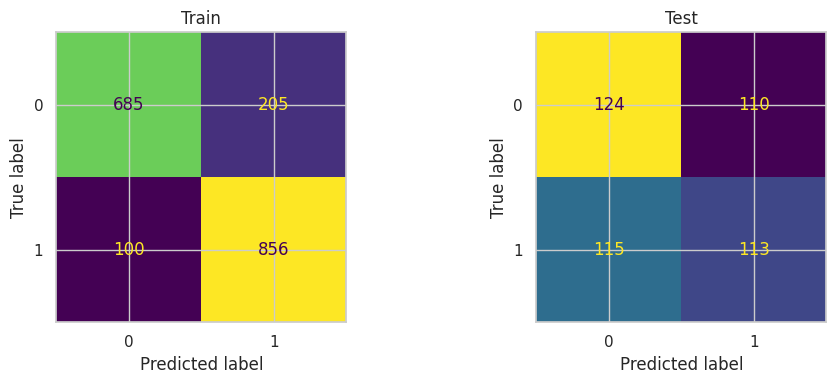

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay(confusion_matrix(y_train, final_model.predict(X_train))).plot(ax=axes[0], colorbar=False)
axes[0].set_title('Train')
ConfusionMatrixDisplay(confusion_matrix(y_test, final_pred)).plot(ax=axes[1], colorbar=False)
axes[1].set_title('Test')
plt.tight_layout()
plt.show()

### Feature importance финальной модели

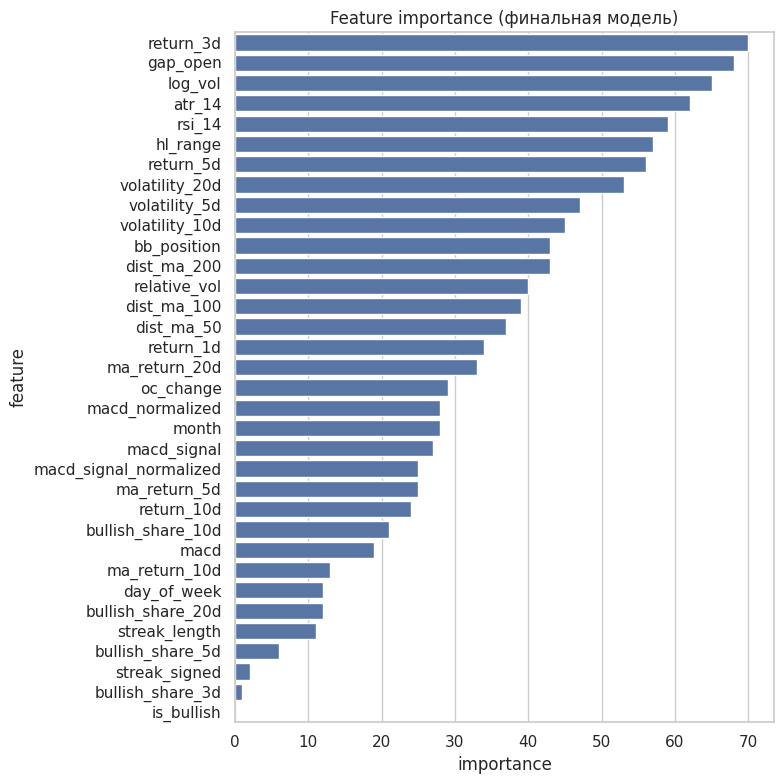

,feature,importance
2,return_3d,70
33,gap_open,68
13,log_vol,65
21,atr_14,62
15,rsi_14,59
5,hl_range,57
3,return_5d,56
12,volatility_20d,53
8,volatility_5d,47
10,volatility_10d,45


In [ ]:
importance = pd.DataFrame({
    'feature': feature_cols,
    'importance': final_model.feature_importances_
}).sort_values('importance', ascending=False)

plt.figure(figsize=(8, 8))
sns.barplot(data=importance, x='importance', y='feature')
plt.title('Feature importance (финальная модель)')
plt.tight_layout()
plt.show()

importance.head(10)

### 8.4 Permutation test для ROC-AUC финальной модели

Проверка, мог ли наблюдаемый ROC-AUC (0.5077) возникнуть случайно, если между признаками и target на самом деле нет никакой связи. Перемешиваем y_test много раз, каждый раз считаем ROC-AUC на тех же предсказаниях.

Наблюдаемый ROC-AUC: 0.5077
Среднее AUC под случайной перестановкой: 0.5005 (± 0.0270)
p-value: 0.4018


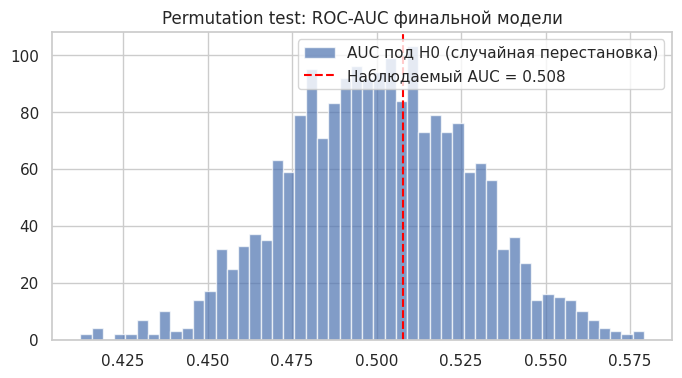

In [ ]:
n_permutations = 2000
rng = np.random.RandomState(RANDOM_STATE)

observed_auc = roc_auc_score(y_test, final_proba)
permuted_aucs = np.array([
    roc_auc_score(rng.permutation(y_test.values), final_proba)
    for _ in range(n_permutations)
])

p_value = (np.sum(permuted_aucs >= observed_auc) + 1) / (n_permutations + 1)

print(f'Наблюдаемый ROC-AUC: {observed_auc:.4f}')
print(f'Среднее AUC под случайной перестановкой: {permuted_aucs.mean():.4f} (± {permuted_aucs.std():.4f})')
print(f'p-value: {p_value:.4f}')

plt.figure(figsize=(8, 4))
plt.hist(permuted_aucs, bins=50, alpha=0.7, label='AUC под H0 (случайная перестановка)')
plt.axvline(observed_auc, color='red', linestyle='--', label=f'Наблюдаемый AUC = {observed_auc:.3f}')
plt.legend()
plt.title('Permutation test: ROC-AUC финальной модели')
plt.show()

## 9. Прямая статистическая проверка сигнала

Проверяем напрямую, есть ли линейная связь между признаками и целевой переменной. Это не зависит от выбора модели или гиперпараметров и служит независимым подтверждением (или опровержением) выводов разделов 7-8.

In [ ]:
corr_with_target = X_train.corrwith(y_train).sort_values(key=abs, ascending=False)
print('Корреляция признаков с target (train):')
print(corr_with_target)

n = len(X_train)
print(f'\nПри n={n} {len(feature_cols)} признаков: единичная корреляция формально значима')
print('примерно от |r| > 2/sqrt(n) =', round(2 / np.sqrt(n), 4),
      '- но при проверке', len(feature_cols), 'признаков одновременно',
      'нужна поправка на множественные сравнения,',
      'а не один фиксированный порог.')

Корреляция признаков с target (train):
atr_14                   -0.063652
volatility_20d           -0.063444
volatility_10d           -0.056398
is_bullish                0.054045
relative_vol              0.051178
volatility_5d            -0.045676
streak_signed             0.036266
log_vol                   0.034816
macd                      0.031828
macd_signal               0.031104
macd_signal_normalized    0.028182
oc_change                 0.027986
month                     0.027777
dist_ma_50                0.026133
macd_normalized           0.025746
dist_ma_100               0.025290
return_1d                 0.025086
bullish_share_3d          0.023823
dist_ma_200               0.023794
ma_return_20d             0.022683
return_5d                 0.021720
bb_position               0.019810
bullish_share_5d          0.019600
ma_return_5d              0.018597
bullish_share_20d         0.018161
day_of_week              -0.016722
return_3d                -0.009931
hl_range        

## 10. Итоговые выводы

**Задача:** по историческим дневным OHLCV-данным предсказать, закроется ли следующий торговый день не ниже цены своего открытия (бычья свеча) или ниже (медвежья).

**Проверка постановки задачи:** точная формула target выверена эмпирически ([раздел 3](#scrollTo=2f62069b)) и подтверждена на 100% строк: `target(t) = [close(t+1) >= open(t+1)]`. Это напрямую определило состав признаков в [разделе 5](#scrollTo=Y_-flL9vERWB).

**Методология:**
- 34 признака: трендовые/моментум-индикаторы (доходности, волатильность, RSI, MACD с нормализованной версией, Bollinger Bands, ATR, дистанции от MA50/100/200, календарные эффекты) и признаки паттерна направления свечей (`is_bullish`, длина серии подряд идущих бычьих/медвежьих дней, доля бычьих дней в скользящем окне, гэп на открытии).
- Time-based train/test split и TimeSeriesSplit - без утечки данных через скользящие окна.
- Несколько независимых проверок: baseline, регуляризованный градиентный бустинг с early stopping, систематический перебор 108 гиперпараметров с финальной проверкой лучшей конфигурации на test, прямая статистика (корреляции).

**Результаты:**

| Метод | Результат (test) |
|---|---|
| Логистическая регрессия | ROC-AUC 0.511 |
| LightGBM без регуляризации | train accuracy 0.868 vs test 0.506 - переобучение |
| LightGBM + early stopping | ROC-AUC 0.462 (best_iteration=1, предсказания близки к константным) |
| TimeSeriesSplit, 5 окон | ROC-AUC 0.504 ± 0.026 |
| Grid search, 108 конфигураций × 5 окон | лучший результат ROC-AUC 0.512 ± 0.023 внутри CV |
| Лучшая конфигурация, финальная проверка на test | ROC-AUC 0.508, accuracy 0.513, precision/recall сбалансированы по обоим классам |
| Максимальная \|corr\| с target (34 признака) | 0.064 (`atr_14`), `is_bullish` - 0.054 |
| Permutation test (финальная модель, 2000 перестановок) | p-value = 0.40 |

**Интерпретация:** ни один из проверенных подходов не показал ROC-AUC заметно выше 0.5 на независимом test. На данном датасете, интервале времени, наборе из 34 признаков и протестированных моделях не удалось обнаружить устойчивую out-of-sample способность предсказывать направление свечи следующего дня. Максимальная корреляция признака с target (0.064) сама по себе не мала относительно порога $2/\sqrt{n} \approx 0.047$, но при одновременной проверке 34 признаков нужна поправка на множественные сравнения - без неё единичное наблюдение недостаточно для вывода о наличии устойчивого сигнала.

Признаки паттерна направления свечей (`is_bullish`, серии, доля бычьих дней) не показали более сильной связи с target, чем трендовые индикаторы - `is_bullish` занял 4-е место по силе корреляции (0.054), выше порога $2/\sqrt n$, но ниже признаков волатильности, и это не меняет общую картину. Гипотеза "направление свечи объясняется инерцией направления предыдущих свечей" эмпирически не подтвердилась. Permutation test подтверждает это формально: p-value = 0.40 для наблюдаемого ROC-AUC (0.508) против распределения под нулевой гипотезой отсутствия связи - различие статистически незначимо.

Результат не противоречит гипотезе слабой формы эффективности рынка, однако сам эксперимент не является её строгой проверкой.

**Ограничения и возможные направления развития:**
- Использовались только цена и объём одного актива - без внешних факторов (макроэкономика, новостной фон, связанные активы/индексы).
- Признаки паттерна направления свечей проверены только в линейной форме (корреляция) и в составе общего набора признаков модели. Отдельная проверка нелинейных взаимодействий именно между ними (без трендовых индикаторов) не проводилась и могла бы быть следующим шагом.